# Evaluación de modelos

### Importación de librerías

In [1]:
import pandas as pd
from pathlib import Path
import joblib
import numpy as np
from pmdarima import auto_arima
from arch import arch_model
from sklearn.metrics import mean_absolute_error
import copy
import matplotlib.pyplot as plt

import sys
import os
sys.path.insert(0, os.path.abspath("../scripts"))
from modelo_SARFIMA import ModeloSARFIMA, pesos_diferenciacion_fraccional

### Importación de datos

In [2]:
df = pd.read_csv('../datos_procesados/entrenamiento.csv', index_col=0)
df_etiquetas = pd.read_csv('../datos_procesados/entrenamiento_etiquetas.csv', index_col=0)
etiquetas = pd.read_csv('../datos_crudos/target_pairs.csv')

In [3]:
df.head(2)

,US_Stock_NEM_adj_close,FX_CHFJPY,US_Stock_XOM_adj_close,US_Stock_ALB_adj_close,FX_EURJPY,JPX_Platinum_Standard_Futures_Close,FX_EURAUD,US_Stock_URA_adj_close,FX_CADCHF,US_Stock_OKE_adj_close,...,FX_NOKJPY,FX_EURCHF,FX_NZDUSD,FX_AUDCAD,US_Stock_SCCO_adj_close,US_Stock_HES_adj_close,FX_AUDUSD,US_Stock_WMB_adj_close,FX_NOKUSD,US_Stock_BKR_adj_close
date_id,,,,,,,,,,,,,,,,,,,,,
0,3.416395,4.749668,4.095014,4.783912,4.908602,8.139441,0.432021,2.559767,-0.252477,3.525210,...,2.626315,0.158934,-0.342165,-0.020610,3.553315,3.755879,-0.244121,3.023848,-2.094385,3.257966
1,3.407974,4.746975,4.114464,4.785887,4.907290,8.139441,0.428469,2.561675,-0.250153,3.541362,...,2.631036,0.160315,-0.344013,-0.018001,3.555154,3.787758,-0.244905,3.051091,-2.092689,3.297510


###  Separación de entrenamiento y prueba.

In [4]:
filas = df.shape[0]
n = int(filas*0.9)
train = df.iloc[:n]
test = df.iloc[n:]

### Separación de variables

In [5]:
etiquetas['etiquetas'] = [x.split(' - ') for x in etiquetas['pair']]
etiquetas.head(2)

,target,lag,pair,etiquetas
0,target_0,1,US_Stock_VT_adj_close,[US_Stock_VT_adj_close]
1,target_1,1,LME_PB_Close - US_Stock_VT_adj_close,"[LME_PB_Close, US_Stock_VT_adj_close]"


### Función que busca el nombre del modelo

In [6]:
def buscar_modelo(nombres):

    algoritmos = ['GARCH', 'SARIMA', 'SARFIMA']
    archivos = []
    tipos = []

    for nombre in nombres:
        for algoritmo in algoritmos:
            nombre_archivo = f"{algoritmo}_{nombre}.joblib"
            if (Path('../modelos') / nombre_archivo).is_file():
                archivos.append(nombre_archivo)

                if algoritmo == 'SARIMA':
                    tipos.append(1)
                elif algoritmo == 'SARFIMA':
                    tipos.append(2)
                else:
                    tipos.append(3)

    return archivos, tipos

### Colocando los nombres de archivos en etiquetas

In [7]:
etiquetas[['archivos', 'tipos']] = pd.DataFrame(etiquetas['etiquetas'].apply(buscar_modelo).tolist(), index=etiquetas.index)
etiquetas.head(2)

,target,lag,pair,etiquetas,archivos,tipos
0,target_0,1,US_Stock_VT_adj_close,[US_Stock_VT_adj_close],[SARIMA_US_Stock_VT_adj_close.joblib],[1]
1,target_1,1,LME_PB_Close - US_Stock_VT_adj_close,"[LME_PB_Close, US_Stock_VT_adj_close]","[SARIMA_LME_PB_Close.joblib, SARIMA_US_Stock_V...","[1, 1]"


### Funciones de actualización.

In [8]:
def actualizar_sarfima(modelo, valor_real):

    # Recuperar el historial anterior
    historia = np.asarray(modelo.historia, dtype=float)

    # Incorporar la nueva observación real
    historia_nueva = np.append(historia, valor_real)

    # Calcular los pesos de diferenciación fraccionaria
    pesos = pesos_diferenciacion_fraccional(d=modelo.d_fraccional, n=len(historia_nueva))

    # Calcular solamente la nueva observación diferenciada
    valor_diferenciado = np.dot(pesos, historia_nueva[::-1])

    # Actualizar el modelo de la serie diferenciada
    modelo.modelo.update(y=[valor_diferenciado], maxiter=0)

    # Actualizar el historial original
    modelo.historia = historia_nueva

    return modelo

### Función de predicción

In [9]:
def predecir(modelo, tipo, pasos):

    if tipo == 1:  # SARIMA
        prediccion = modelo.predict(n_periods=pasos)

    elif tipo == 2:  # SARFIMA
        prediccion = modelo.predict(n_periods=pasos)

    elif tipo == 3:  # GARCH
        resultado = modelo.forecast(horizon=pasos, start=None, reindex=False)
        prediccion = resultado.mean.iloc[-1].to_numpy()

    else:
        raise ValueError("Tipo inválido. Usa 1, 2 o 3.")

    return prediccion

### Función que busca los índices que se usarán de df_etiquetas para medir métricas

In [10]:
def indices_etiquetas(lag):
    x = n - 1
    y = filas - n + lag + 1
    return x, y

### Colocando los índices y pasos de predicción

In [11]:
etiquetas[['indice_prueba', 'pasos']] = pd.DataFrame(etiquetas['lag'].apply(indices_etiquetas).tolist(), index=etiquetas.index)
etiquetas.head(2)

,target,lag,pair,etiquetas,archivos,tipos,indice_prueba,pasos
0,target_0,1,US_Stock_VT_adj_close,[US_Stock_VT_adj_close],[SARIMA_US_Stock_VT_adj_close.joblib],[1],1763,199
1,target_1,1,LME_PB_Close - US_Stock_VT_adj_close,"[LME_PB_Close, US_Stock_VT_adj_close]","[SARIMA_LME_PB_Close.joblib, SARIMA_US_Stock_V...","[1, 1]",1763,199


### Función que carga modelos

In [12]:
def cargar_modelo(nombre_archivo):

    ruta = Path('../modelos') / nombre_archivo

    return joblib.load(ruta)

### Funciones principales para generar generar métricas

In [13]:
def prediccion_serie(nombre_serie):

    # Carga del modelo.
    archivos, tipos = buscar_modelo(nombre_serie)
    modelo = cargar_modelo(archivos[0])

    # Datos reales
    y_real = df[nombre_serie][n:]

    # Predicción de datos
    y_pred = predecir(modelo, tipos[0], filas - n)

    return y_real, y_pred

In [14]:
def prediccion_etiqueta(serie_etiqueta):

    # Reglas de cálculo.
    target = serie_etiqueta['target']
    lag = serie_etiqueta['lag']
    archivos = serie_etiqueta['archivos']
    tipos = serie_etiqueta['tipos']
    indice_prueba = serie_etiqueta['indice_prueba']
    pasos = int(serie_etiqueta['pasos']) + 1
    cantidad_modelos = len(archivos)

    # Carga de modelos
    modelo_1 = cargar_modelo(archivos[0])
    if cantidad_modelos == 2:
        modelo_2 = cargar_modelo(archivos[1])

    # Datos reales
    y_real = df_etiquetas[target][indice_prueba:]

    # Predicción de datos
    y_1 = predecir(modelo_1, tipos[0], pasos + int(lag) - 1)
    y_1_diff = (y_1[lag:] - y_1[:-lag])[:-lag] 
    if cantidad_modelos == 2:
        y_2 = predecir(modelo_2, tipos[1], pasos + int(lag) - 1)
        y_2_diff = (y_2[lag:] - y_2[:-lag])[:-lag]

    if cantidad_modelos == 2:
        y_pred = y_1_diff - y_2_diff
        return y_real, y_pred
    else:
        y_pred = y_1_diff
        return y_real, y_pred

### Predicciones simuladas

In [15]:
def predecir_simulado(modelo, tipo, pasos, semilla=0):
    if tipo == 1:  # SARIMA
        resultado = modelo.arima_res_ if hasattr(modelo, "arima_res_") else modelo
        prediccion = resultado.simulate(nsimulations=pasos, anchor="end", random_state=semilla)
    elif tipo == 2:  # SARFIMA
        resultado = modelo.modelo.arima_res_ if hasattr(modelo.modelo, "arima_res_") else modelo.modelo
        pred_diff = np.asarray(resultado.simulate(nsimulations=pasos, anchor="end", random_state=semilla)).flatten()
        historia = list(np.asarray(modelo.historia, dtype=float))
        pesos = pesos_diferenciacion_fraccional(modelo.d_fraccional, len(historia) + pasos)
        prediccion = []
        for z_t in pred_diff:
            t = len(historia)
            y_t = z_t - np.dot(pesos[1:t+1], historia[::-1])
            historia.append(y_t)
            prediccion.append(y_t)
    elif tipo == 3:  # GARCH
        rng = np.random.default_rng(semilla)
        resultado = modelo.forecast(horizon=pasos, reindex=False)
        media = resultado.mean.iloc[-1].to_numpy()
        desviacion = np.sqrt(resultado.variance.iloc[-1].to_numpy())
        prediccion = media + rng.normal(0, 1, pasos) * desviacion
    else:
        raise ValueError("Tipo inválido. Usa 1, 2 o 3.")
    return np.asarray(prediccion).flatten()

In [16]:
def prediccion_serie_simulado(nombre_serie):

    # Carga del modelo.
    archivos, tipos = buscar_modelo(nombre_serie)
    modelo = cargar_modelo(archivos[0])

    # Datos reales
    y_real = df[nombre_serie][n:]

    # Predicción de datos
    y_pred = predecir_simulado(modelo, tipos[0], filas - n)

    return y_real, y_pred

In [17]:
def prediccion_etiqueta_simulado(serie_etiqueta):

    # Reglas de cálculo.
    target = serie_etiqueta['target']
    lag = serie_etiqueta['lag']
    archivos = serie_etiqueta['archivos']
    tipos = serie_etiqueta['tipos']
    indice_prueba = serie_etiqueta['indice_prueba']
    pasos = int(serie_etiqueta['pasos']) + 1
    cantidad_modelos = len(archivos)

    # Carga de modelos
    modelo_1 = cargar_modelo(archivos[0])
    if cantidad_modelos == 2:
        modelo_2 = cargar_modelo(archivos[1])

    # Datos reales
    y_real = df_etiquetas[target][indice_prueba:]

    # Predicción de datos
    y_1 = predecir_simulado(modelo_1, tipos[0], pasos + int(lag) - 1)
    y_1_diff = (y_1[lag:] - y_1[:-lag])[:-lag] 
    if cantidad_modelos == 2:
        y_2 = predecir_simulado(modelo_2, tipos[1], pasos + int(lag) - 1)
        y_2_diff = (y_2[lag:] - y_2[:-lag])[:-lag]

    if cantidad_modelos == 2:
        y_pred = y_1_diff - y_2_diff
        return y_real, y_pred
    else:
        y_pred = y_1_diff
        return y_real, y_pred

### Errores de las series

In [18]:
df_series = pd.DataFrame(index=df.columns, data={"error": -1.0})
modelos = []

for serie in df_series.index:
    y_real, y_pred = prediccion_serie_simulado([serie])
    df_series.loc[serie, 'error'] = mean_absolute_error(y_real, y_pred)

    _, tipo = buscar_modelo([serie])

    if tipo[0] == 1:
        modelos.append('SARIMA')
    elif tipo[0] == 2:
        modelos.append('SARFIMA')
    else:
        modelos.append('GARCH')

df_series['mejor_modelo'] = modelos

c:\Users\rod18907\Desktop\PROYECTO_2_DS\PROYECTO_2_DS\.venv\Lib\site-packages\pmdarima\arima\arima.py:869: UserWarning: You've deserialized an ARIMA from a version (2.0.4) that does not match your installed version of pmdarima (2.1.1). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an ARIMA from a version (%s) "
c:\Users\rod18907\Desktop\PROYECTO_2_DS\PROYECTO_2_DS\.venv\Lib\site-packages\pmdarima\arima\arima.py:869: UserWarning: You've deserialized an ARIMA from a version (2.0.4) that does not match your installed version of pmdarima (2.1.1). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an ARIMA from a version (%s) "
c:\Users\rod18907\Desktop\PROYECTO_2_DS\PROYECTO_2_DS\.venv\Lib\site-packages\pmdarima\arima\arima.py:869: UserWarning: You've deserialized an ARIMA from a version (2.0.4) that does not match your installed version of pmdarima (2.1.1). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an AR

In [19]:
df_series = df_series.reset_index(drop=False)
df_series.columns = ['serie', 'error', 'mejor_modelo']

In [20]:
df_series.describe()

,error
count,106.000000
mean,0.170042
std,0.144268
min,0.014718
25%,0.058438
50%,0.125754
75%,0.262095
max,0.774465


In [21]:
### Mejores modelos con errores simulados
#df_series.to_csv('../errores_modelos/mejores_modelos_simulando.csv', index=False)

In [22]:
mejor_serie = df_series.iloc[df_series['error'].idxmin()]['serie']
peor_serie = df_series.iloc[df_series['error'].idxmax()]['serie']

### Errores de las etiquetas

In [23]:
MAES = []

for rows in etiquetas.index:
    row = etiquetas.loc[rows]
    y_real, y_pred = prediccion_etiqueta_simulado(row)
    MAES.append(mean_absolute_error(y_real, y_pred))

etiquetas['MAE'] = MAES

c:\Users\rod18907\Desktop\PROYECTO_2_DS\PROYECTO_2_DS\.venv\Lib\site-packages\pmdarima\arima\arima.py:869: UserWarning: You've deserialized an ARIMA from a version (2.0.4) that does not match your installed version of pmdarima (2.1.1). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an ARIMA from a version (%s) "
c:\Users\rod18907\Desktop\PROYECTO_2_DS\PROYECTO_2_DS\.venv\Lib\site-packages\pmdarima\arima\arima.py:869: UserWarning: You've deserialized an ARIMA from a version (2.0.4) that does not match your installed version of pmdarima (2.1.1). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an ARIMA from a version (%s) "
c:\Users\rod18907\Desktop\PROYECTO_2_DS\PROYECTO_2_DS\.venv\Lib\site-packages\pmdarima\arima\arima.py:869: UserWarning: You've deserialized an ARIMA from a version (2.0.4) that does not match your installed version of pmdarima (2.1.1). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an AR

In [24]:
etiquetas.describe()

,lag,indice_prueba,pasos,MAE
count,424.000000,424.0,424.000000,424.000000
mean,2.500000,1763.0,200.500000,0.085512
std,1.119355,0.0,1.119355,0.056747
min,1.000000,1763.0,199.000000,0.008882
25%,1.750000,1763.0,199.750000,0.029876
50%,2.500000,1763.0,200.500000,0.079673
75%,3.250000,1763.0,201.250000,0.130991
max,4.000000,1763.0,202.000000,0.322224


In [25]:
### Guardando las etiquetas
#etiquetas.to_csv('../errores_modelos/etiquetas_errores_simulado.csv', index=False)

In [26]:
mejor_etiqueta = etiquetas['MAE'].idxmin()
peor_etiqueta = etiquetas['MAE'].idxmax()

### Gráficas

In [27]:
def graficar_lineas(y_real, y_pred):
    plt.figure(figsize=(12, 5))
    plt.plot(np.arange(len(y_real)), y_real, label="Valores reales", color="blue")
    plt.plot(np.arange(len(y_pred)), y_pred, label="Predicciones", color="red")
    plt.title("Valores reales vs. predicciones")
    plt.xlabel("Periodo")
    plt.ylabel("Valor")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

#### Mejor serie gráfica

In [28]:
mejor_serie

'FX_AUDCAD'

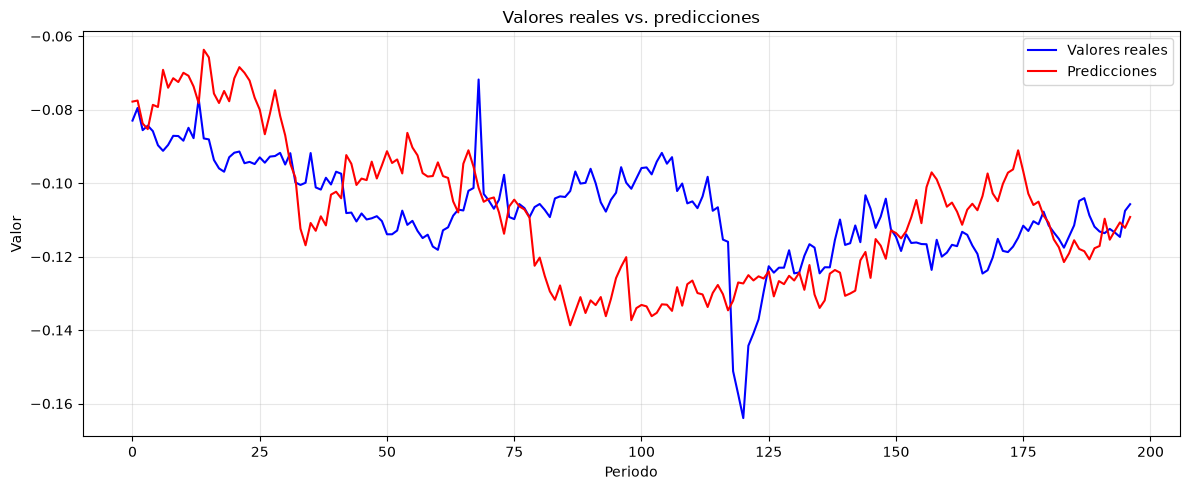

In [29]:
y_real, y_pred = prediccion_serie_simulado([mejor_serie])
graficar_lineas(y_real, y_pred)

### Peor serie gráfica

In [30]:
peor_serie

'FX_AUDJPY'

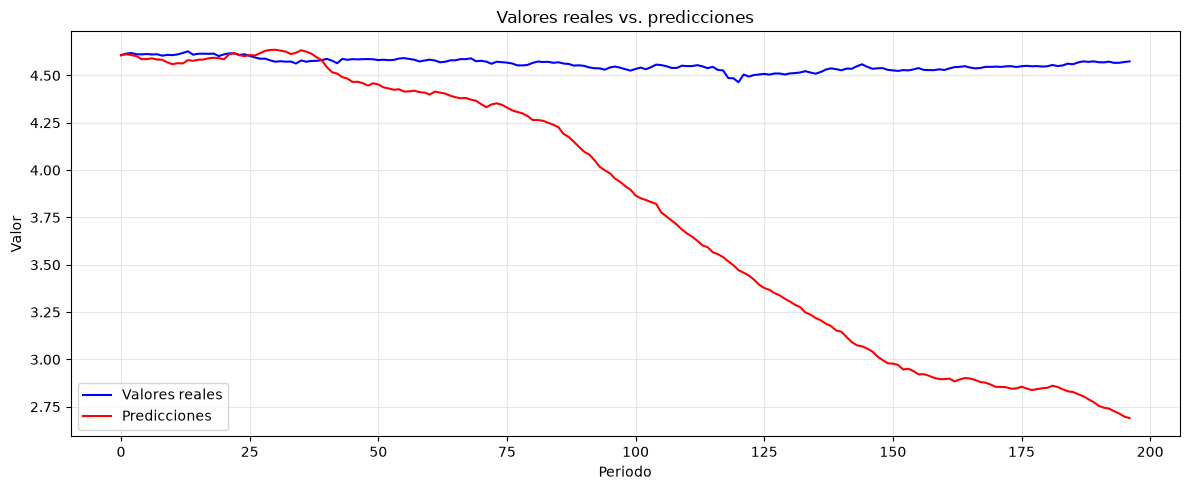

In [31]:
y_real, y_pred = prediccion_serie_simulado([peor_serie])
graficar_lineas(y_real, y_pred)

### Mejor etiqueta gráfica

In [32]:
etiquetas.loc[mejor_etiqueta]['target']

'target_68'

c:\Users\rod18907\Desktop\PROYECTO_2_DS\PROYECTO_2_DS\.venv\Lib\site-packages\pmdarima\arima\arima.py:869: UserWarning: You've deserialized an ARIMA from a version (2.0.4) that does not match your installed version of pmdarima (2.1.1). This could cause unforeseen behavior.
  warnings.warn("You've deserialized an ARIMA from a version (%s) "


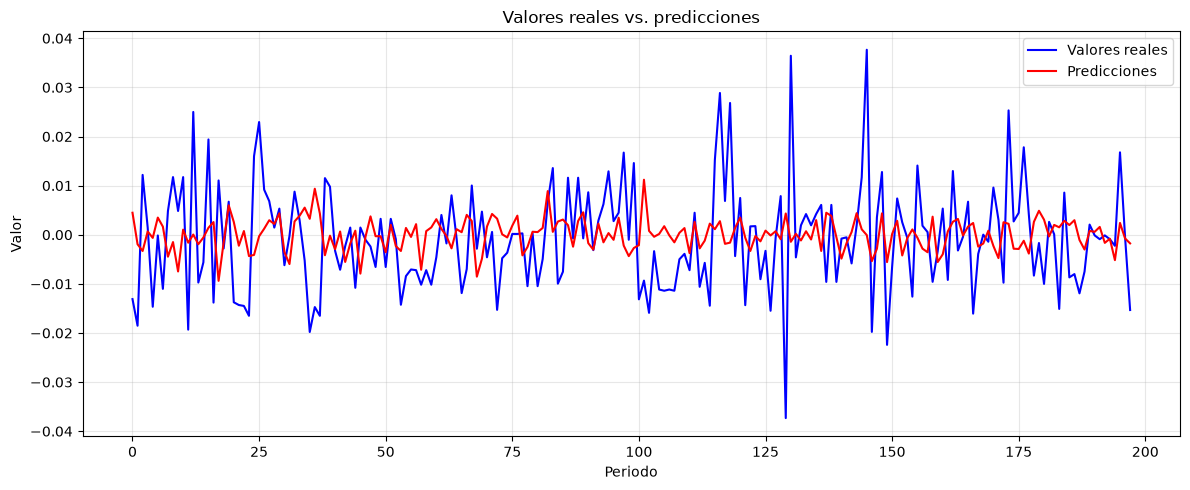

In [33]:
y_real, y_pred = prediccion_etiqueta_simulado(etiquetas.iloc[mejor_etiqueta])
graficar_lineas(y_real, y_pred)

### Peor etiqueta gráfica

In [34]:
etiquetas.loc[peor_etiqueta]['target']

'target_276'

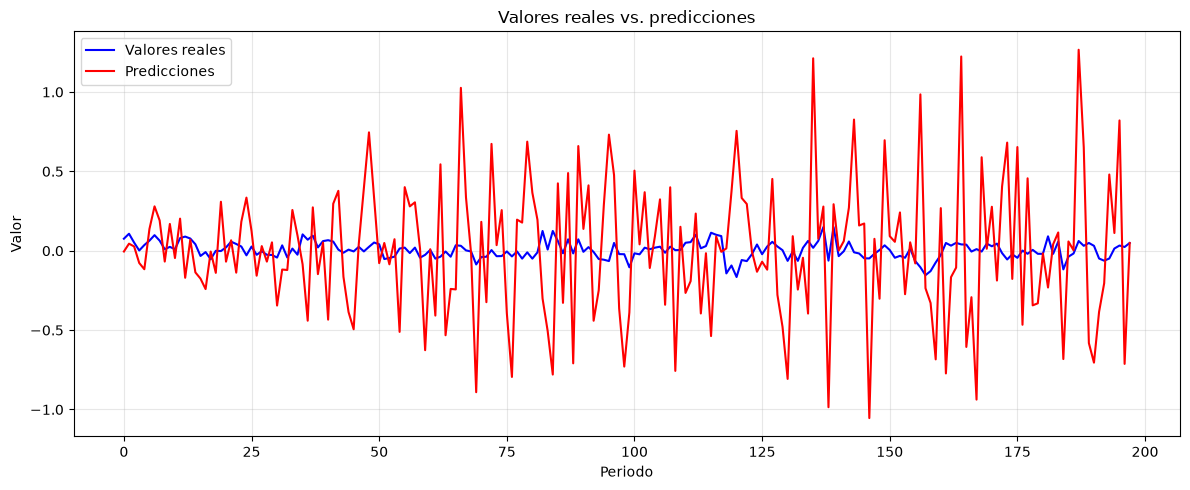

In [35]:
y_real, y_pred = prediccion_etiqueta_simulado(etiquetas.iloc[peor_etiqueta])
graficar_lineas(y_real, y_pred)